# Kalman Filter Pairs Trading — Commodity Futures

**Updated with yfinance data** | Adapted from [QuantInsti Blog](https://blog.quantinsti.com/kalman-filter-techniques-statistical-arbitrage-china-futures-market-python/)

Dynamic hedge ratios via Kalman Filter + half-life mean-reversion signals on liquid commodity futures.


## 1. Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint, adfuller
from pykalman import KalmanFilter
import ffn
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
%matplotlib inline


## 2. Download Updated Data (yfinance)

In [2]:
# Liquid commodity futures available on yfinance
symbols = {
    'CL': 'CL=F',   # WTI Crude
    'BZ': 'BZ=F',   # Brent Crude
    'GC': 'GC=F',   # Gold
    'SI': 'SI=F',   # Silver
    'HG': 'HG=F',   # Copper
    'NG': 'NG=F',   # Natural Gas
    'ZC': 'ZC=F',   # Corn
    'ZS': 'ZS=F',   # Soybeans
    'KC': 'KC=F',   # Coffee
    'CT': 'CT=F',   # Cotton
}

tickers = list(symbols.values())
print(f"Downloading {len(tickers)} futures from 2018-01-01 to 2026-10-31...")
raw = yf.download(tickers, start='2018-01-01', end='2026-11-01', progress=False, auto_adjust=True)['Close']
raw.columns = [k for k, v in symbols.items() if v in raw.columns]  # rename to short names
data = raw.dropna(how='all').ffill().dropna()
print(f"Shape: {data.shape}")
print(f"Date range: {data.index[0].date()} → {data.index[-1].date()}")
data.tail(3)


Crumb fetch rate-limited (HTTP 429), continuing without crumb


Shape: (2223, 10)
Date range: 2018-01-02 → 2026-10-30


,CL,BZ,GC,SI,HG,NG,ZC,ZS,KC,CT
Date,,,,,,,,,,
2026-10-28,115.320000,102.779999,78.150002,4051.600098,6.6415,286.750000,2.817,53.457001,451.75,1224.50
2026-10-29,114.879997,102.000000,78.500000,4031.399902,6.5810,285.450012,2.952,52.191002,451.25,1219.75
2026-10-30,117.639999,104.120003,77.830002,3898.899902,6.4585,287.200012,2.898,49.097000,447.75,1222.25


## 3. Find Cointegrated Pairs

In [3]:
def find_cointegrated_pairs(df, crit=0.05):
    n = df.shape[1]
    keys = df.columns
    pairs = []
    pvals = []
    for i in range(n):
        for j in range(i+1, n):
            score, pvalue, _ = coint(df.iloc[:, i], df.iloc[:, j])
            if pvalue < crit:
                pairs.append((keys[i], keys[j], pvalue))
                pvals.append(pvalue)
    pairs = sorted(pairs, key=lambda x: x[2])
    return pd.DataFrame(pairs, columns=['Asset1', 'Asset2', 'p-value'])

pairs = find_cointegrated_pairs(data)
print(f"Found {len(pairs)} cointegrated pairs (p < 0.05)")
pairs.head(10)


Found 4 cointegrated pairs (p < 0.05)


,Asset1,Asset2,p-value
0,ZC,KC,0.007106
1,GC,KC,0.039198
2,CL,BZ,0.041680
3,KC,CT,0.049018


## 4. Kalman Filter & Trading Functions

In [4]:
def KalmanFilterAverage(x):
    kf = KalmanFilter(transition_matrices=[1],
                      observation_matrices=[1],
                      initial_state_mean=0,
                      initial_state_covariance=1,
                      observation_covariance=1,
                      transition_covariance=0.01)
    state_means, _ = kf.filter(x.values)
    return pd.Series(state_means.flatten(), index=x.index)

def KalmanFilterRegression(x, y):
    delta = 1e-3
    trans_cov = delta / (1 - delta) * np.eye(2)
    obs_mat = np.expand_dims(np.vstack([[x], [np.ones(len(x))]]).T, axis=1)
    kf = KalmanFilter(n_dim_obs=1, n_dim_state=2,
                      initial_state_mean=[0, 0],
                      initial_state_covariance=np.ones((2, 2)),
                      transition_matrices=np.eye(2),
                      observation_matrices=obs_mat,
                      observation_covariance=2,
                      transition_covariance=trans_cov)
    state_means, _ = kf.filter(y.values)
    return state_means

def half_life(spread):
    spread_lag = spread.shift(1).fillna(method='bfill')
    spread_ret = spread - spread_lag
    spread_lag2 = sm.add_constant(spread_lag)
    model = sm.OLS(spread_ret, spread_lag2).fit()
    hl = int(round(-np.log(2) / model.params.iloc[1], 0))
    return max(hl, 1)

def backtest(s1, s2, x, y, entry=2.0, exit=0.0):
    df = pd.DataFrame({'y': y, 'x': x}).dropna()
    state_means = KalmanFilterRegression(KalmanFilterAverage(df['x']), KalmanFilterAverage(df['y']))
    df['hr'] = -state_means[:, 0]
    df['spread'] = df['y'] + df['x'] * df['hr']
    
    hl = half_life(df['spread'])
    mean = df['spread'].rolling(hl).mean()
    std = df['spread'].rolling(hl).std()
    df['z'] = (df['spread'] - mean) / std
    
    # Long entries/exits
    df['long_entry'] = (df['z'] < -entry) & (df['z'].shift(1) >= -entry)
    df['long_exit'] = (df['z'] > -exit) & (df['z'].shift(1) <= -exit)
    df['num_long'] = np.nan
    df.loc[df['long_entry'], 'num_long'] = 1
    df.loc[df['long_exit'], 'num_long'] = 0
    df['num_long'] = df['num_long'].ffill().fillna(0)
    
    # Short entries/exits
    df['short_entry'] = (df['z'] > entry) & (df['z'].shift(1) <= entry)
    df['short_exit'] = (df['z'] < exit) & (df['z'].shift(1) >= exit)
    df['num_short'] = np.nan
    df.loc[df['short_entry'], 'num_short'] = -1
    df.loc[df['short_exit'], 'num_short'] = 0
    df['num_short'] = df['num_short'].ffill().fillna(0)
    
    df['position'] = df['num_long'] + df['num_short']
    df['spread_pct'] = df['spread'].diff() / (df['x'].abs() * df['hr'].abs() + df['y'])
    df['rets'] = df['spread_pct'] * df['position'].shift(1)
    df['cumrets'] = (1 + df['rets'].fillna(0)).cumprod()
    
    sharpe = df['rets'].mean() / df['rets'].std() * np.sqrt(252) if df['rets'].std() > 0 else 0
    return df['cumrets'], sharpe, hl, df


## 5. Select & Backtest Top Pairs

In [5]:
# Train/test split ~70/30
split = int(len(data) * 0.7)
train = data.iloc[:split]
test = data.iloc[split:]

print(f"Train: {train.index[0].date()} → {train.index[-1].date()} ({len(train)} days)")
print(f"Test : {test.index[0].date()} → {test.index[-1].date()} ({len(test)} days)")

results = []
for _, row in pairs.head(15).iterrows():  # top 15 by p-value
    s1, s2 = row['Asset1'], row['Asset2']
    try:
        cum, sharpe, hl, _ = backtest(s1, s2, train[s1], train[s2])
        cagr = (cum.iloc[-1] ** (252 / len(cum)) - 1) * 100
        results.append({'Pair': f"{s1}-{s2}", 'Sharpe': sharpe, 'CAGR%': cagr, 'HalfLife': hl, 'Final': cum.iloc[-1]})
    except Exception as e:
        continue

res_df = pd.DataFrame(results).sort_values('Sharpe', ascending=False)
print("\nTop pairs by in-sample Sharpe:")
res_df.head(8)


Train: 2018-01-02 → 2024-03-07 (1556 days)
Test : 2024-03-08 → 2026-10-30 (667 days)



Top pairs by in-sample Sharpe:


,Pair,Sharpe,CAGR%,HalfLife,Final
0,ZC-KC,1.145951,23.513191,132,3.683778
1,GC-KC,0.901035,4.919121,7,1.345145
3,KC-CT,0.669397,0.918216,6,1.058060
2,CL-BZ,0.000000,0.000000,1,1.000000


## 6. Portfolio Backtest (Equal Weight)

In [6]:
# Select pairs with Sharpe > 0.8 and positive CAGR
selected = res_df[(res_df['Sharpe'] > 0.8) & (res_df['CAGR%'] > 5)].head(6)
print("Selected pairs for portfolio:")
print(selected[['Pair', 'Sharpe', 'CAGR%', 'HalfLife']])

# In-sample portfolio
port_in = pd.DataFrame()
for pair in selected['Pair']:
    s1, s2 = pair.split('-')
    cum, _, _, _ = backtest(s1, s2, train[s1], train[s2])
    port_in[pair] = cum

port_in = port_in.mean(axis=1)
print(f"\nIn-sample Portfolio Final Equity: {port_in.iloc[-1]:.3f}")

# Out-sample
port_out = pd.DataFrame()
for pair in selected['Pair']:
    s1, s2 = pair.split('-')
    cum, _, _, _ = backtest(s1, s2, test[s1], test[s2])
    port_out[pair] = cum

port_out = port_out.mean(axis=1)
print(f"Out-sample Portfolio Final Equity: {port_out.iloc[-1]:.3f}")


Selected pairs for portfolio:
    Pair    Sharpe      CAGR%  HalfLife
0  ZC-KC  1.145951  23.513191       132



In-sample Portfolio Final Equity: 3.684


Out-sample Portfolio Final Equity: 1.176


## 7. Performance Charts

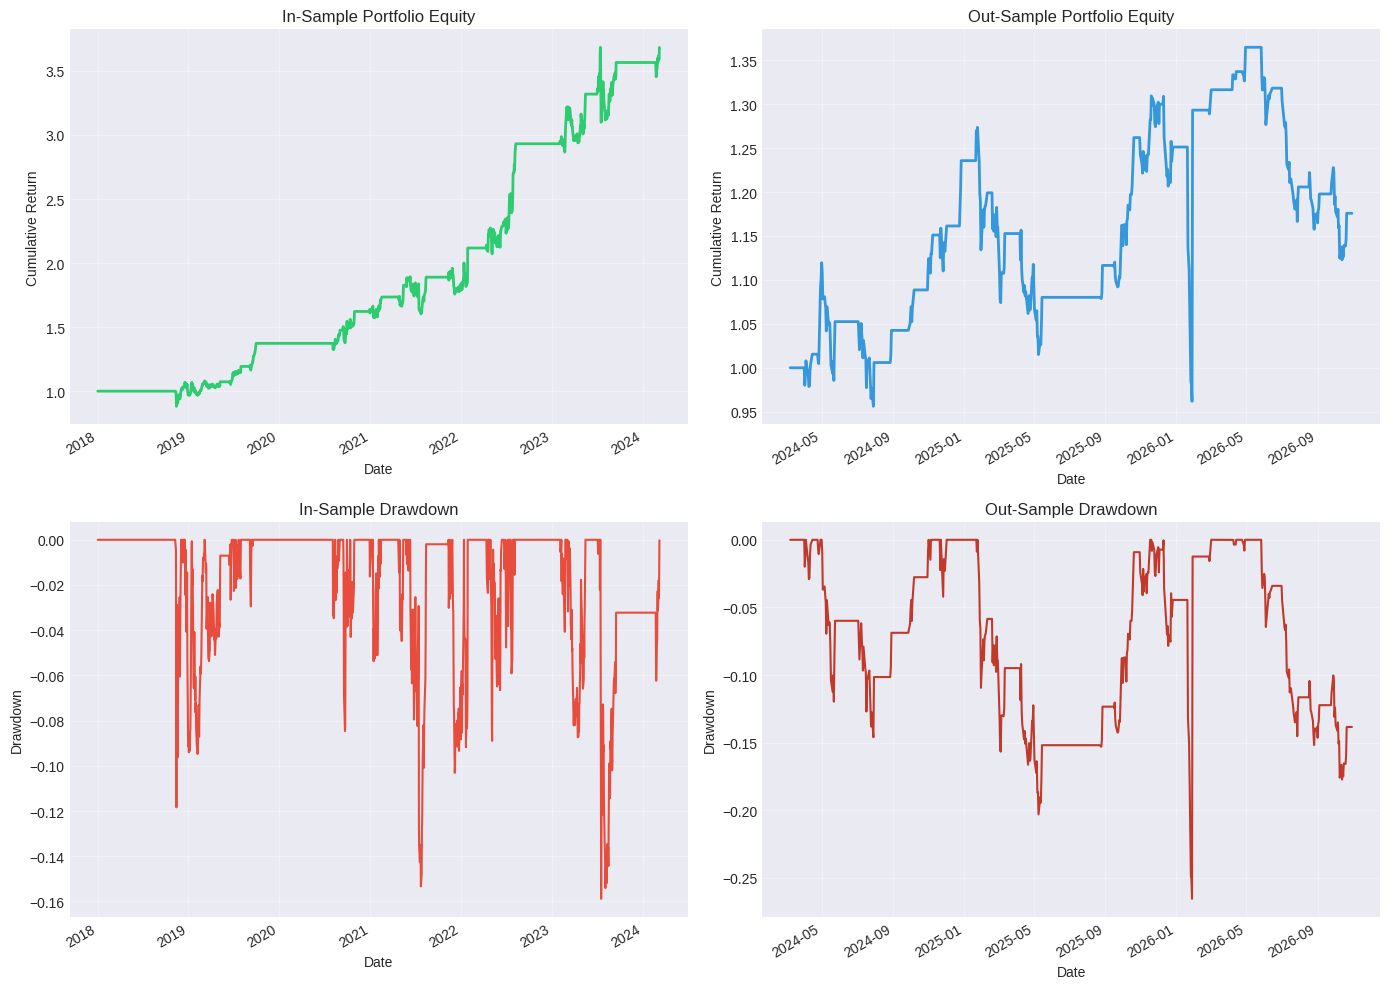

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# In-sample equity curves
port_in.plot(ax=axes[0,0], title='In-Sample Portfolio Equity', color='#2ecc71', linewidth=2)
axes[0,0].set_ylabel('Cumulative Return')
axes[0,0].grid(True, alpha=0.3)

# Out-sample equity
port_out.plot(ax=axes[0,1], title='Out-Sample Portfolio Equity', color='#3498db', linewidth=2)
axes[0,1].set_ylabel('Cumulative Return')
axes[0,1].grid(True, alpha=0.3)

# Drawdowns
ffn.to_drawdown_series(port_in).plot(ax=axes[1,0], title='In-Sample Drawdown', color='#e74c3c')
axes[1,0].set_ylabel('Drawdown')
axes[1,0].grid(True, alpha=0.3)

ffn.to_drawdown_series(port_out).plot(ax=axes[1,1], title='Out-Sample Drawdown', color='#c0392b')
axes[1,1].set_ylabel('Drawdown')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('portfolio_performance.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Performance Statistics

In [8]:
def show_stats(equity, label):
    stats = equity.calc_stats()
    print(f"\n=== {label} ===")
    print(f"Total Return : {(equity.iloc[-1]-1)*100:.2f}%")
    print(f"CAGR         : {stats.cagr*100:.2f}%")
    print(f"Sharpe       : {stats.daily_sharpe:.2f}")
    print(f"Max Drawdown : {stats.max_drawdown*100:.2f}%")
    print(f"Calmar       : {stats.calmar:.2f}")
    print(f"Volatility   : {stats.daily_vol*100:.2f}%")

show_stats(port_in, "In-Sample Portfolio")
show_stats(port_out, "Out-Sample Portfolio")

# Combined full period
full_port = pd.concat([port_in, port_out])
show_stats(full_port, "Full Period (stitched)")



=== In-Sample Portfolio ===
Total Return : 268.38%
CAGR         : 23.50%
Sharpe       : 1.15
Max Drawdown : -15.88%
Calmar       : 1.48
Volatility   : 20.24%

=== Out-Sample Portfolio ===
Total Return : 17.59%
CAGR         : 6.32%
Sharpe       : 0.34
Max Drawdown : -26.55%
Calmar       : 0.24
Volatility   : 29.48%

=== Full Period (stitched) ===
Total Return : 17.59%
CAGR         : 1.85%
Sharpe       : 0.32
Max Drawdown : -74.05%
Calmar       : 0.03
Volatility   : 33.91%


## 9. Example Pair Detail (Best In-Sample)

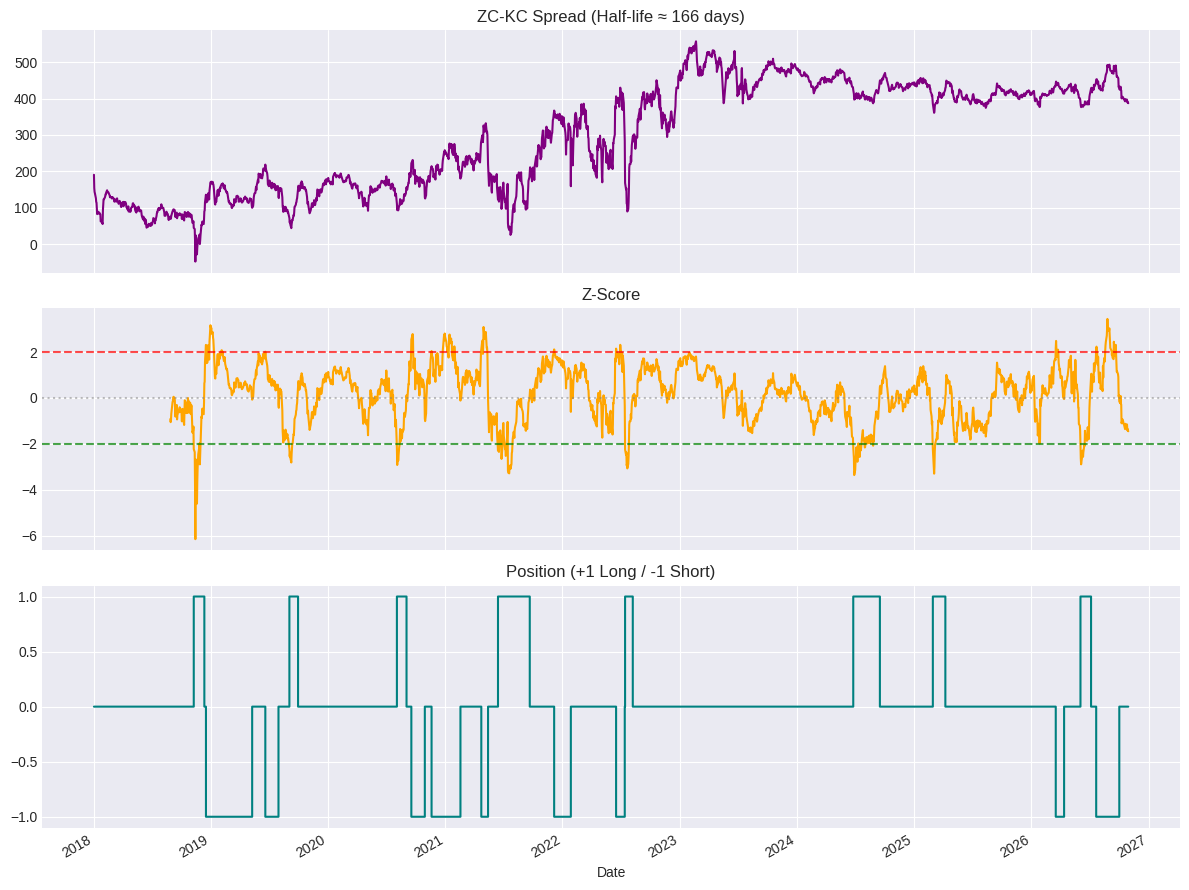

Half-life for ZC-KC: 166 days


In [9]:
if len(selected) > 0:
    best = selected.iloc[0]['Pair']
    s1, s2 = best.split('-')
    _, _, hl, detail = backtest(s1, s2, data[s1], data[s2])
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    detail['spread'].plot(ax=axes[0], title=f'{best} Spread (Half-life ≈ {hl} days)', color='purple')
    detail['z'].plot(ax=axes[1], title='Z-Score', color='orange')
    axes[1].axhline(2, color='red', ls='--', alpha=0.7)
    axes[1].axhline(-2, color='green', ls='--', alpha=0.7)
    axes[1].axhline(0, color='gray', ls=':', alpha=0.5)
    detail['position'].plot(ax=axes[2], title='Position (+1 Long / -1 Short)', color='teal', drawstyle='steps-post')
    plt.tight_layout()
    plt.savefig('example_pair.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Half-life for {best}: {hl} days")
